# Experiment Design & Power Analysis (statsmodels)

Most failed A/B tests fail before the first user sees the treatment. The test is too small to detect the effect, or
the team picks the success metric after it sees the data. **Experiment design** fixes these decisions in advance:
the hypothesis, the unit, the metrics, the sample size and the duration. **Power analysis** computes the sample
size. This lesson plans a follow-up e-mail test with the real baselines of the Hillstrom experiment.

**After this lesson you can:**

1. Write a testable hypothesis and choose the unit of randomization.
2. Separate primary, secondary and guardrail metrics, and define an OEC.
3. Compute the sample size from the MDE, alpha and power, by formula and with `statsmodels.stats.power`.
4. Convert a sample size into a test duration from a traffic assumption.
5. Check a power calculation with a simulation.
6. Explain why heavy-tailed metrics and unequal splits need more users.

**Data:** Hillstrom MineThatData E-Mail Analytics challenge (2008): 64,000 customers in a randomized e-mail test.
The lesson uses its control group as the baseline for planning.

**Services:** none.

In [1]:
import math
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", category=UserWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.power import NormalIndPower, TTestIndPower
from statsmodels.stats.proportion import proportion_effectsize

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: pinned datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
rng = np.random.default_rng(2)

df = pd.read_csv(datasets.fetch("hillstrom_email.csv"))
ctrl = df[df.segment == "No E-Mail"]
base = pd.DataFrame({
    "mean": [ctrl.visit.mean(), ctrl.conversion.mean(), ctrl.spend.mean()],
    "std": [ctrl.visit.std(), ctrl.conversion.std(), ctrl.spend.std()],
}, index=["visit", "conversion", "spend"])
base["cv"] = base["std"] / base["mean"]                 # coefficient of variation
print(f"control group: {len(ctrl):,} customers (two-week outcomes)")
print(base.round(4).to_string())

control group: 21,306 customers (two-week outcomes)
              mean      std       cv
visit       0.1062   0.3081   2.9016
conversion  0.0057   0.0755  13.1775
spend       0.6528  11.5882  17.7518


These are the baselines for planning. The visit rate is 10.6 %, and the conversion rate is 0.57 %. The mean spend
is 0.65 dollars per customer, with a standard deviation of 11.59 dollars. The last column is the **coefficient of
variation** (CV), the standard deviation divided by the mean. Section 6 shows that the CV sets the sample size.

## 1. The Design Decisions

The marketing team wants to test a new version of the men's e-mail. Before any power calculation, write down these
decisions:

1. **Hypothesis.** *Compared with no e-mail, the new e-mail increases the mean spend per customer in the 14 days
   after the send.* A good hypothesis names the change, the metric, the direction and the time window.
2. **Unit of randomization.** The **unit** is the entity that the test assigns to an arm. Here it is the customer.
   The analysis unit must be the same as the randomization unit. If the test randomizes customers but analyses
   sessions, the sessions of one customer are not independent, and the p-values are too small.
3. **Metrics.** Put each metric in one of three classes:

| class | role | e-mail example |
| :--- | :--- | :--- |
| **primary** | decides the test; one metric (or a fixed formula) | spend per customer, 14 days |
| **secondary** | explains the primary result; no decision alone | visit rate, conversion rate |
| **guardrail** | must not get worse; stops a harmful launch | unsubscribe rate, spam complaints |

The **Overall Evaluation Criterion** (OEC) is the primary metric or a weighted combination of metrics that the
organization agrees to optimize. It must move in the short test window and predict long-term value. Spend per
customer is a candidate OEC. Unsubscribes are a long-term cost, so they are a guardrail. The Hillstrom data has no
unsubscribe column, so this lesson plans for the three metrics in the table above.

## 2. The Sample Size Formula

Four numbers set the sample size:

- $\alpha$, the significance level (the Type I error rate), usually 0.05, two-sided.
- The **power** $1 - \beta$, the probability to detect a real effect of the planned size, usually 0.80.
- The **minimum detectable effect** (MDE) $\delta$, the smallest effect that is worth detecting.
- The standard deviation $\sigma$ of the metric.

For a difference in means with equal groups, the sample size **per group** is:

$$
n = \frac{(z_{1-\alpha/2} + z_{1-\beta})^2 \, (\sigma_C^2 + \sigma_T^2)}{\delta^2}
\;\approx\; \frac{2\,(z_{1-\alpha/2} + z_{1-\beta})^2 \, \sigma^2}{\delta^2}
$$

With $\alpha = 0.05$ and power 0.80, $(1.96 + 0.84)^2 = 7.85$. This gives the common shortcut
$n \approx 16\,\sigma^2/\delta^2$. For a rate $p$, $\sigma^2 = p(1-p)$.

statsmodels works with a standardized **effect size**: Cohen's $d = \delta / \sigma$ for means, and Cohen's
$h = 2\arcsin\sqrt{p_T} - 2\arcsin\sqrt{p_C}$ for proportions. `NormalIndPower` uses the normal distribution;
`TTestIndPower` uses the t distribution, which matters only for small samples.

In [2]:
ALPHA, POWER, REL_MDE = 0.05, 0.80, 0.10           # plan: detect a 10 % relative lift
z_sum = stats.norm.ppf(1 - ALPHA / 2) + stats.norm.ppf(POWER)
print(f"(z_0.975 + z_0.80)^2 = {z_sum**2:.2f}")

rows = []
for metric in base.index:
    mu, sd = base.loc[metric, "mean"], base.loc[metric, "std"]
    delta = REL_MDE * mu
    n_formula = 2 * z_sum**2 * sd**2 / delta**2
    if metric == "spend":
        es = delta / sd                                                   # Cohen's d
        n_sm = TTestIndPower().solve_power(effect_size=es, alpha=ALPHA, power=POWER, ratio=1)
    else:
        es = proportion_effectsize(mu * (1 + REL_MDE), mu)                # Cohen's h
        n_sm = NormalIndPower().solve_power(effect_size=es, alpha=ALPHA, power=POWER, ratio=1)
    rows.append([metric, mu, mu + delta, es, math.ceil(n_formula), math.ceil(n_sm)])
plan = pd.DataFrame(rows, columns=["metric", "baseline", "target", "effect_size", "n_formula", "n_statsmodels"])
print(plan.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

(z_0.975 + z_0.80)^2 = 7.85
    metric  baseline  target  effect_size  n_formula  n_statsmodels
     visit    0.1062  0.1168       0.0337      13217          13788
conversion    0.0057  0.0063       0.0074     272588         285959
     spend    0.6528  0.7181       0.0056     494680         494679


To detect a 10 % relative lift with 80 % power:

- **visit** (10.6 % to 11.7 %) needs about 13,800 customers per group.
- **conversion** (0.57 % to 0.63 %) needs about 286,000 customers per group.
- **spend** (0.65 to 0.72 dollars) needs about 495,000 customers per group.

For spend, the formula and statsmodels agree. For the rates, statsmodels gives about 4 % more. The reason: the
shortcut uses the control variance $p_C(1-p_C)$ for both groups, but the higher treatment rate has a higher variance. The Hillstrom
test had about 21,300 customers per arm. It was large enough for a 10 % lift in visits, but far too small for a
10 % lift in spend.

## 3. MDE and Power Curves

A team often has a fixed number of users and asks the reverse question: what is the smallest effect that this
sample can detect? Solve the formula for $\delta$:

$$
\text{MDE} = (z_{1-\alpha/2} + z_{1-\beta}) \, \sqrt{\sigma_C^2/n + \sigma_T^2/n} \;\approx\; 2.80 \, \sigma \sqrt{2/n}
$$

The MDE falls with $1/\sqrt{n}$. Four times more users halve the MDE. The cell computes the relative MDE for each
metric with statsmodels and draws the MDE and power curves.

In [3]:
n_grid = np.unique(np.logspace(3, 6.5, 60).astype(int))

def rel_mde(metric, n):
    # relative MDE that n users per group can detect (alpha 0.05, power 0.80)
    mu, sd = base.loc[metric, "mean"], base.loc[metric, "std"]
    d = NormalIndPower().solve_power(nobs1=n, alpha=ALPHA, power=POWER, ratio=1)   # detectable Cohen's d
    return d * sd / mu

n_hill = len(ctrl)
for metric in base.index:
    print(f"{metric:>10}: relative MDE with {n_hill:,} per group = {100 * rel_mde(metric, n_hill):5.1f} %")

def power_at(metric, n, lift):
    mu, sd = base.loc[metric, "mean"], base.loc[metric, "std"]
    return NormalIndPower().power(effect_size=lift * mu / sd, nobs1=n, alpha=ALPHA, ratio=1)

print(f"power for a 10 % lift in visit at n = {n_hill:,}: {power_at('visit', n_hill, 0.10):.3f}; "
      f"in spend: {power_at('spend', n_hill, 0.10):.3f}")

     visit: relative MDE with 21,306 per group =   7.9 %
conversion: relative MDE with 21,306 per group =  35.8 %
     spend: relative MDE with 21,306 per group =  48.2 %
power for a 10 % lift in visit at n = 21,306: 0.945; in spend: 0.090


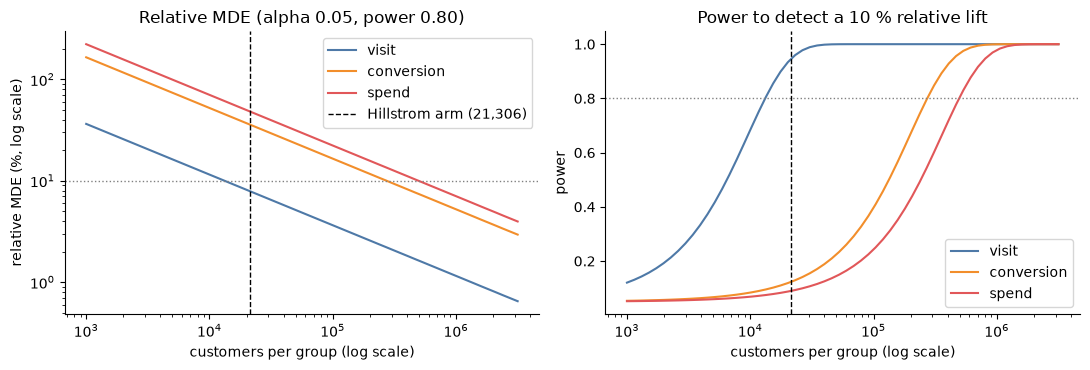

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
colors = {"visit": "#4E79A7", "conversion": "#F28E2B", "spend": "#E15759"}
for metric in base.index:
    ax[0].plot(n_grid, [100 * rel_mde(metric, n) for n in n_grid], color=colors[metric], label=metric)
    ax[1].plot(n_grid, [power_at(metric, n, 0.10) for n in n_grid], color=colors[metric], label=metric)
ax[0].axhline(10, color="grey", ls=":", lw=1)
ax[0].axvline(n_hill, color="black", ls="--", lw=1, label=f"Hillstrom arm ({n_hill:,})")
ax[0].set(xscale="log", yscale="log", title="Relative MDE (alpha 0.05, power 0.80)",
          xlabel="customers per group (log scale)", ylabel="relative MDE (%, log scale)")
ax[1].axhline(0.8, color="grey", ls=":", lw=1)
ax[1].axvline(n_hill, color="black", ls="--", lw=1)
ax[1].set(xscale="log", title="Power to detect a 10 % relative lift", xlabel="customers per group (log scale)",
          ylabel="power")
ax[0].legend(); ax[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

With 21,306 customers per group, the test can detect a lift of 7.9 % in visits. For conversion, the MDE is 36 %,
and for spend it is 48 %. The power curves show the same result from the other side. At the Hillstrom size, the
power for a 10 % lift is 0.945 for visit and only 0.09 for spend.

The real Hillstrom effects were large: the men's e-mail raised visits by 72 % and spend by 118 % (Lesson 01). A
follow-up test that compares two e-mail versions expects much smaller differences. That test needs many more users.

*Insight: Before the test, state the MDE that the planned sample can detect. If the MDE is larger than any
realistic effect, the test can only produce a non-significant result. Then it is better to change the metric, the
sample size or the design.*

## 4. From Sample Size to Duration

The sample size becomes a duration through the traffic. **Assumption** (not from the data): the shop can add
**8,000 eligible customers per day** to the test, and the test has two arms. The cell computes the days and rounds
up to full weeks.

In [5]:
DAILY_USERS = 8_000                                  # ASSUMPTION: eligible customers per day, all arms together
ARMS = 2
for _, r in plan.iterrows():
    days = math.ceil(ARMS * r.n_statsmodels / DAILY_USERS)
    weeks = math.ceil(days / 7)
    print(f"{r.metric:>10}: {ARMS} x {r.n_statsmodels:>7,} customers -> {days:>4} days -> run {weeks:>3} full weeks")

     visit: 2 x  13,788 customers ->    4 days -> run   1 full weeks
conversion: 2 x 285,959 customers ->   72 days -> run  11 full weeks
     spend: 2 x 494,679 customers ->  124 days -> run  18 full weeks


A test on visits needs 4 days, so it runs one full week. A test on spend with a 10 % MDE needs 124 days, about 18
weeks, at this traffic. Round up to full weeks, because user behaviour differs between weekdays and weekends. A test
that runs from Monday to Thursday measures only weekday users.

A duration of 18 weeks has its own problems: the product changes during the test, users clear cookies, and the
business waits. If the duration is too long, choose a larger MDE, a more sensitive metric or a variance reduction
method such as CUPED (Lesson 05).

## 5. Simulation Check

A power calculation is a formula with assumptions. A simulation checks it directly. Generate many experiments with
the planned effect and the planned $n$. Run the planned test and count how often it rejects $H_0$. This share is
the power.

The first check is for visit. It draws binomial counts with the real baseline rate and a 10 % lift. The second
check is for spend, which is far from normal. It treats the real control group and the real women's e-mail group as
the two populations. The real difference in mean spend is the effect. The check resamples customers from each group
with replacement.

In [6]:
N_SIM = 2000

# check 1: visit, binomial draws at the planned n
n_v = int(plan.set_index("metric").loc["visit", "n_statsmodels"])
p_c = base.loc["visit", "mean"]; p_t = p_c * (1 + REL_MDE)
x_c = rng.binomial(n_v, p_c, N_SIM); x_t = rng.binomial(n_v, p_t, N_SIM)
pp = (x_c + x_t) / (2 * n_v)
z = (x_t - x_c) / n_v / np.sqrt(pp * (1 - pp) * 2 / n_v)
power_sim = np.mean(2 * stats.norm.sf(np.abs(z)) < ALPHA)
print(f"visit: n = {n_v:,} per group, planned power 0.80, simulated power {power_sim:.3f} "
      f"(+/- {1.96 * np.sqrt(power_sim * (1 - power_sim) / N_SIM):.3f})")

# check 2: spend, resampling the real control and women's e-mail groups
spend_c = ctrl.spend.to_numpy()
spend_t = df.loc[df.segment == "Womens E-Mail", "spend"].to_numpy()
delta = spend_t.mean() - spend_c.mean()
sd_pooled = np.sqrt((spend_c.var(ddof=1) + spend_t.var(ddof=1)) / 2)
n_s = math.ceil(TTestIndPower().solve_power(effect_size=delta / sd_pooled, alpha=ALPHA, power=POWER))
print(f"spend: real effect {delta:.3f} $ ({100 * delta / spend_c.mean():.0f} % lift), pooled sd {sd_pooled:.2f} $ "
      f"-> n = {n_s:,} per group")
p_vals = []
for _ in range(N_SIM // 200):
    a = spend_c[rng.integers(0, len(spend_c), (200, n_s))]
    b = spend_t[rng.integers(0, len(spend_t), (200, n_s))]
    p_vals.append(stats.ttest_ind(b, a, axis=1, equal_var=False).pvalue)
p_vals = np.concatenate(p_vals)
print(f"spend: simulated power {np.mean(p_vals < ALPHA):.3f} "
      f"(+/- {1.96 * np.sqrt(0.8 * 0.2 / N_SIM):.3f}) with the Welch t-test on resampled real customers")

visit: n = 13,788 per group, planned power 0.80, simulated power 0.803 (+/- 0.017)
spend: real effect 0.424 $ (65 % lift), pooled sd 13.47 $ -> n = 15,809 per group


spend: simulated power 0.814 (+/- 0.018) with the Welch t-test on resampled real customers


Both simulations agree with the plan. For visit, 13,788 customers per group give a simulated power of 0.803. For
spend, the real effect of the women's e-mail is 0.42 dollars, a lift of 65 %. The statsmodels plan for it is 15,809 customers
per group. The simulation on resampled real customers gives a power of 0.814, inside the error band. Each simulated group has more
than 15,000 customers, so the normal approximation holds even for spend, where 99 % of the values are 0.

## 6. Why Spend Needs So Many More Users

Divide the formula by $\mu^2$ and write the MDE as a relative lift $r = \delta / \mu$:

$$
n \approx \frac{2\,(z_{1-\alpha/2} + z_{1-\beta})^2 \, \text{CV}^2}{r^2}, \qquad \text{CV} = \sigma / \mu
$$

For the same relative lift, $n$ grows with the square of the CV. A spend metric has a high CV for two reasons. Most
customers spend 0, and a few customers spend several hundred dollars. The cell compares the CVs and shows the effect
of **capping** (winsorizing): values above a high percentile are set to that percentile.

In [7]:
cv = base["cv"]
print(f"CV: visit {cv['visit']:.2f}, conversion {cv['conversion']:.2f}, spend {cv['spend']:.2f}")
print(f"n(spend) / n(visit) for the same relative lift = (CV ratio)^2 = {(cv['spend'] / cv['visit'])**2:.1f}")

buyers = spend_c[spend_c > 0]
print(f"buyers in control: {len(buyers)} of {len(spend_c):,} | buyer spend: median {np.median(buyers):.0f} $, "
      f"max {buyers.max():.0f} $")
for cap in [None, 400, 200]:
    s = spend_c if cap is None else np.minimum(spend_c, cap)
    n_cap = 2 * z_sum**2 * (s.std(ddof=1) / s.mean())**2 / REL_MDE**2
    print(f"cap {str(cap):>4} $: mean {s.mean():.3f} $, CV {s.std(ddof=1) / s.mean():5.2f}, "
          f"n for a 10 % lift = {n_cap:>9,.0f}")

CV: visit 2.90, conversion 13.18, spend 17.75
n(spend) / n(visit) for the same relative lift = (CV ratio)^2 = 37.4
buyers in control: 122 of 21,306 | buyer spend: median 88 $, max 499 $
cap None $: mean 0.653 $, CV 17.75, n for a 10 % lift =   494,679
cap  400 $: mean 0.639 $, CV 17.31, n for a 10 % lift =   470,151
cap  200 $: mean 0.554 $, CV 15.51, n for a 10 % lift =   377,867


The CV of spend is 17.8, six times the CV of visit (2.9). The required sample grows with the square, so spend
needs about 37 times more customers than visit for the same relative lift. Only 122 control customers bought
anything, and the largest purchase is 499 dollars.

Capping helps, but the CV stays high, because the zeros also cause a large part of the variance. A cap at 200
dollars reduces $n$ by 24 %, and the CV is still 15.5. Capping also changes the metric: the test then measures
"capped spend". Write the cap in the analysis plan before the test. CUPED (Lesson 05) and a better metric choice
(Lesson 04) are the other tools to reduce $n$.

*Insight: The sample size depends on the CV of the metric, not on its importance. Revenue metrics have a high CV,
so they need far more users than click or visit metrics to detect the same relative lift.*

## 7. The Cost of Unequal Splits

Teams sometimes put only 10 % of the users into the treatment to limit the risk. The variance of the difference
is $\sigma^2 (1/n_T + 1/n_C)$. For a total of $N$ users with a treatment share $f$:

$$
\operatorname{Var}(\hat\delta) = \frac{\sigma^2}{N\, f\,(1-f)}
$$

$f(1-f)$ is largest at $f = 0.5$. A 90/10 split has $f(1-f) = 0.09$ instead of 0.25. So it needs
$0.25 / 0.09 = 2.8$ times more users in total. statsmodels takes the split as `ratio` $= n_2 / n_1$.

In [8]:
h_visit = proportion_effectsize(p_c * (1 + REL_MDE), p_c)
rows = []
for share_t in [0.5, 0.3, 0.2, 0.1, 0.05]:
    ratio = (1 - share_t) / share_t                              # control size / treatment size
    n_t = NormalIndPower().solve_power(effect_size=h_visit, alpha=ALPHA, power=POWER, ratio=ratio)
    total = n_t * (1 + ratio)
    rows.append([f"{100 * share_t:.0f}/{100 * (1 - share_t):.0f}", math.ceil(n_t), math.ceil(n_t * ratio),
                 math.ceil(total), 0.25 / (share_t * (1 - share_t))])
split = pd.DataFrame(rows, columns=["treatment/control %", "n_treatment", "n_control", "n_total", "theory_factor"])
split["factor_vs_50_50"] = split.n_total / split.n_total[0]
split["days_at_8000_per_day"] = np.ceil(split.n_total / DAILY_USERS).astype(int)
print("plan for a 10 % lift in visit:")
print(split.round(2).to_string(index=False))

plan for a 10 % lift in visit:
treatment/control %  n_treatment  n_control  n_total  theory_factor  factor_vs_50_50  days_at_8000_per_day
              50/50        13788      13788    27575           1.00             1.00                     4
              30/70         9848      22979    32827           1.19             1.19                     5
              20/80         8617      34468    43085           1.56             1.56                     6
              10/90         7660      68936    76596           2.78             2.78                    10
               5/95         7257     137872   145129           5.26             5.26                    19


A 90/10 split needs 76,596 customers in total instead of 27,575 for 50/50, which is 2.8 times more. The test runs
10 days instead of 4. The statsmodels factors match the formula $0.25 / (f(1-f))$. A 95/5 split costs 5.3 times
more. A small treatment share reduces the risk for users, but it buys this safety with a longer test. A
common alternative is a short ramp-up: start at 5 %, check the guardrails, then move to 50/50 for the measurement.

The same logic applies to designs with more arms. Hillstrom used three equal arms. Each pairwise comparison then
uses two thirds of the users, and a multiple comparison correction (Lesson 01) increases $n$ further.

## 8. Pre-Registration Checklist

Write these items down, with a date, before the first user enters the test:

1. Hypothesis: change, metric, direction, time window.
2. Unit of randomization and unit of analysis (the same).
3. Primary metric (OEC), secondary metrics, guardrail metrics with their limits.
4. MDE, $\alpha$, power, one- or two-sided test, and the resulting $n$ per arm.
5. Duration in full weeks, and the traffic assumption behind it.
6. Split (for example 50/50) and the expected counts per arm, for the sample ratio check (Lesson 06).
7. Analysis method: test, variance reduction (Lesson 05), multiple comparison correction, metric caps.
8. Pre-planned segments, if any. Every other segment result is exploratory.
9. Stopping rule: a fixed horizon, or a sequential method (Lesson 07). No stop on the first significant p-value.
10. The decision rule: what result leads to launch, to no launch, or to a new test.

## Real-World Use Case

Microsoft runs thousands of online controlled experiments each year on its experimentation platform (ExP), for
products such as Bing and Office. The book *Trustworthy Online Controlled Experiments* (Kohavi, Tang and Xu, 2020)
describes the practices of Microsoft, Google and LinkedIn. It recommends to agree on an OEC before the test and to
compute the sample size from a power analysis. It also recommends to run the test for at least one full week,
because of day-of-week effects. Section 4 of this lesson applies the same rule. The book also describes guardrail
metrics, which stop a launch when the treatment harms users or the business.